# Chapitre 1 - Exercices 1.1 à 1.6

Ce notebook traite les six premiers exercices du chapitre 1, centrés sur les systèmes
opérationnels et analytiques, les données dérivées et le coût du cloud :

- **1.1** : classer des charges de travail (raisonnement et mesure sur SQLite) ;
- **1.2** : combien de requêtes analytiques une base OLTP supporte-t-elle ? (calcul
  M/M/c et simulation) ;
- **1.3** : instantanés contre flux de modifications (calcul et simulation) ;
- **1.4** : dimensionner l'écriture d'un lac sur un object store (calcul) ;
- **1.5** : graphe de dérivation, recalculs et effacement (mini-lab) ;
- **1.6** : où bascule le choix entre cloud et auto-hébergement ? (calcul analytique
  et vérification numérique).

In [1]:
import math
import sqlite3

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

from ddia import architecture as ar
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)
fmt = lambda v: f"{v:,.0f}".replace(",", " ")

## Exercice 1.1 : classer des charges de travail

**Énoncé.** Pour chacune des charges suivantes, dire s'il s'agit d'OLTP, d'analytique
classique (OLAP), d'analytique temps réel intégrée à un produit, ou d'un cas qui justifie
le HTAP. Justifier en une phrase (motif de lecture, motif d'écriture, utilisateur).

1. Afficher le panier d'un client sur le site marchand.
2. Le tableau de bord mensuel du chiffre d'affaires par région, consulté par la direction.
3. Vérifier, au moment d'un paiement, que la carte n'a pas dépassé son plafond quotidien,
   en agrégeant les paiements des dernières 24 heures, puis enregistrer le paiement.
4. Afficher à chaque vendeur d'une place de marché, sur sa page, le nombre de vues de ses
   annonces dans la dernière heure.
5. Un data scientist explore deux ans de clics pour trouver des variables prédictives
   de la résiliation.
6. Mettre à jour l'adresse de livraison d'un client.

Puis, **mesurer** : sur la base de ventes du cours 1, implémenter une requête pour les
charges 1, 2 et 3 et comparer la part de la table examinée par chacune.

**Rappels.** OLTP : requêtes ponctuelles par clé, écritures individuelles, utilisateur
final. OLAP : agrégats sur beaucoup de lignes, requêtes ad hoc, analyste interne.
Analytique temps réel : agrégats à faible latence, ingestion continue, intégrés au produit.
HTAP : une même application a besoin des deux (cours 1, section 3 et cours 2, section 3 ;
sections *Characterizing Transaction Processing and Analytics* et *Data Warehousing*).

**Solution.**

| charge | catégorie | justification |
|---|---|---|
| 1. panier | OLTP | lecture ponctuelle par identifiant client, utilisateur final, faible latence |
| 2. tableau de bord mensuel | OLAP | agrégat sur un mois de ventes, analyste interne, quelques requêtes par jour |
| 3. plafond de carte | HTAP | agrégat (sur les paiements récents de la carte) **et** écriture transactionnelle, dans la même requête utilisateur ; cas typique de la détection de fraude cité par le livre |
| 4. vues par vendeur | analytique temps réel | agrégat sur beaucoup d'événements, mais affiché dans le produit, frais à la minute |
| 5. exploration des clics | OLAP (lac de données) | parcours de deux ans d'historique, ad hoc, souvent hors SQL |
| 6. adresse | OLTP | écriture d'un enregistrement par clé |

Le cas 3 mérite une précision : si l'on dispose d'un index par carte et par date,
l'agrégat ne porte que sur quelques dizaines de lignes et reste une requête OLTP
raisonnable. Il devient un problème « hybride » quand les règles de fraude demandent des
agrégats plus larges (tous les paiements d'un commerçant, d'un pays, d'un type de carte).
Les catégories décrivent des **motifs d'accès**, pas des tables ou des produits.

**Vérification** : on implémente les charges 1 à 3 sur la base du cours 1 (en
interprétant le « panier » comme les achats du jour d'un client, et le « plafond » comme
la somme des achats du client sur les deux derniers jours), et on rapporte le travail au
travail d'un parcours complet de la table.

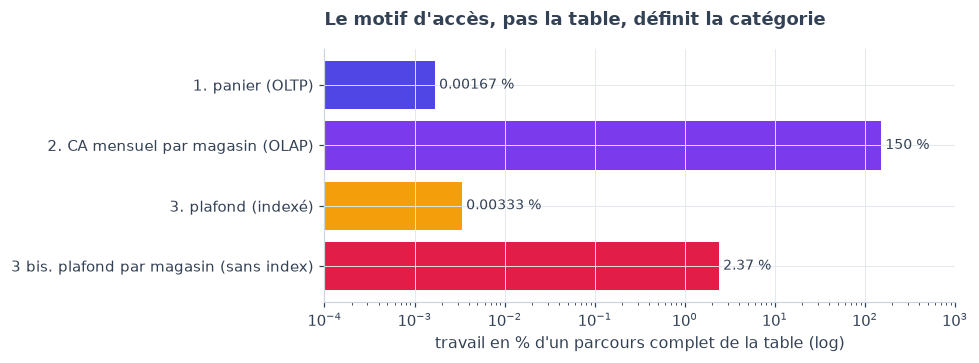

,instructions VM,part d'un parcours complet
1. panier (OLTP),10.0,1.667e-05
2. CA mensuel par magasin (OLAP),898710.0,1.498e+00
3. plafond (indexé),20.0,3.333e-05
3 bis. plafond par magasin (sans index),14210.0,2.370e-02


In [2]:
con = sqlite3.connect(":memory:")
ar.make_shop_db(con, n_sales=150_000, seed=0)
con.execute("CREATE INDEX sales_by_customer_day ON sales (customer_id, day)")
full_scan = ar.vm_steps(con, "SELECT SUM(amount) FROM sales")
Q = {"1. panier (OLTP)": ("SELECT * FROM sales WHERE customer_id = ? AND day = ?", (42, 80)),
     "2. CA mensuel par magasin (OLAP)": ("SELECT store_id, SUM(amount) FROM sales WHERE day BETWEEN 30 AND 59 GROUP BY store_id", ()),
     "3. plafond (indexé)": ("SELECT SUM(amount) FROM sales WHERE customer_id = ? AND day >= ?", (42, 88)),
     "3 bis. plafond par magasin (sans index)": ("SELECT SUM(amount) FROM sales WHERE store_id = ? AND day >= ?", (3, 88))}
res = pd.DataFrame({k: {"instructions VM": ar.vm_steps(con, sql, p),
                        "part d'un parcours complet": ar.vm_steps(con, sql, p) / full_scan} for k, (sql, p) in Q.items()}).T
fig, ax = plt.subplots(figsize=(9, 3.4))
b = ax.barh(res.index[::-1], res["part d'un parcours complet"][::-1] * 100, color=[ROSE, AMBER, VIOLET, INDIGO])
ax.set_xscale("log"); ax.bar_label(b, labels=[f"{v * 100:.3g} %" for v in res["part d'un parcours complet"][::-1]], padding=3, fontsize=9)
ax.set_xlim(1e-4, 1e3)
ax.set_xlabel("travail en % d'un parcours complet de la table (log)")
ax.set_title("Le motif d'accès, pas la table, définit la catégorie")
plt.tight_layout(); plt.show()
res

Le panier et le plafond indexé ne touchent qu'une fraction infime de la table (OLTP) ;
l'agrégat mensuel coûte même plus qu'un parcours complet (il passe par l'index des jours,
puis lit chaque ligne d'un tiers de la table) : c'est de l'OLAP. Le même contrôle de
plafond, formulé sur un critère non indexé (le magasin), fait des centaines de fois plus
de travail que la version indexée : il examine toutes les ventes des deux derniers jours,
tous clients confondus, et son coût croît avec le volume quotidien. C'est exactement ce
qui rend les règles de fraude larges difficiles à servir sur une base OLTP.

> **À retenir.** On classe une charge par son motif d'accès (combien de lignes lues, par
> quelle clé, combien de requêtes, pour qui), pas par la table qu'elle touche. Une même
> question métier peut être OLTP ou analytique selon l'index qui la sert.

## Exercice 1.2 : combien de requêtes analytiques une base OLTP supporte-t-elle ?

**Énoncé.** Une base OLTP a 16 cœurs. Elle reçoit 6 000 requêtes par seconde de durée
moyenne 2 ms (arrivées poissonniennes, durées exponentielles). L'équipe analytique
voudrait lancer directement sur cette base des requêtes qui monopolisent chacune un cœur
pendant 20 secondes.

1. Calculer la charge de la base sans requête analytique, et le temps de réponse moyen
   (modèle M/M/16).
2. L'objectif de niveau de service impose un temps de réponse moyen inférieur à 4 ms. Quel
   est le nombre maximal $k$ de requêtes analytiques simultanées compatible ?
3. Les analystes lancent en moyenne une requête toutes les 30 secondes (arrivées
   poissonniennes). Combien de requêtes analytiques tournent en moyenne ? Avec quelle
   probabilité l'objectif est-il violé à un instant donné ?
4. Conclure, et proposer une architecture.

**Rappels.** Charge $\rho = \lambda / (c\,\mu)$ ; temps de réponse M/M/c par la formule
d'Erlang C (`ar.mmc_response_time`) ; nombre moyen de tâches en cours $= \lambda \times$
durée (loi de Little) ; un nombre de tâches en cours alimentées par un processus de
Poisson à durée fixe suit une loi de Poisson (file M/G/∞) (cours 1, section 4).

**Solution.**

*1.* $\lambda = 6\,000$/s, $\mu = 500$/s par cœur : $\rho = 6\,000 / (16 \times 500) = 0{,}75$.
La formule donne environ 2,1 ms : la file d'attente est encore négligeable.

*2.* Avec $k$ cœurs pris, la charge OLTP devient $12 / (16 - k)$. Il faut $16 - k > 12$,
soit $k \le 3$. Le calcul (ci-dessous) montre que le temps moyen reste sous 4 ms jusqu'à
$k = 3$ (3,4 ms, charge 0,92, déjà au bord de la crosse de hockey) ; à $k = 4$, la charge
atteint 1 et la file diverge. Donc $k_{max} = 3$.

*3.* Loi de Little : $0{,}0333$ requête/s $\times$ 20 s $= 0{,}67$ requête en cours en
moyenne. Le nombre en cours suit une loi de Poisson de moyenne $0{,}67$ :
$P(N \ge 4) = 1 - e^{-0{,}67}(1 + 0{,}67 + 0{,}67^2/2 + 0{,}67^3/6) \approx 0{,}5\,\%$.
L'objectif est violé (base saturée) environ 0,5 % du temps, soit 7 minutes par jour en
épisodes de quelques secondes ; et 3 % du temps ($N \ge 3$), la base est à la limite.

*4.* Une capacité confortable (charge 0,75) ne laisse en réalité que deux cœurs « libres »
au sens de la latence. Il faut séparer : une **réplique de lecture** dédiée à l'analytique
(à peu de frais, mais elle reste une base OLTP mal adaptée aux parcours), ou mieux un
entrepôt alimenté par ETL ou capture de changements.

**Vérification numérique** : formule M/M/c pour $k = 0..4$, loi de Poisson, puis
simulation d'une heure avec des requêtes analytiques aléatoires.

In [3]:
lam, mu, c = 6000.0, 500.0, 16
tab = pd.DataFrame({"k": range(5)})
tab["charge OLTP"] = lam / mu / (c - tab.k)
tab["temps moyen (ms)"] = [ar.mmc_response_time(lam, mu, c - k) * 1e3 for k in tab.k]
m = 20 / 30
tab["P(N = k)"] = [math.exp(-m) * m ** k / math.factorial(k) for k in tab.k]
print(f"P(N >= 3) = {1 - tab['P(N = k)'][:3].sum():.2%} ; P(N >= 4) = {1 - tab['P(N = k)'][:4].sum():.2%}")
tab.set_index("k")

P(N >= 3) = 3.02% ; P(N >= 4) = 0.49%


,charge OLTP,temps moyen (ms),P(N = k)
k,,,
0,0.750,2.102,0.513
1,0.800,2.213,0.342
2,0.857,2.482,0.114
3,0.923,3.409,0.025
4,1.000,inf,0.004


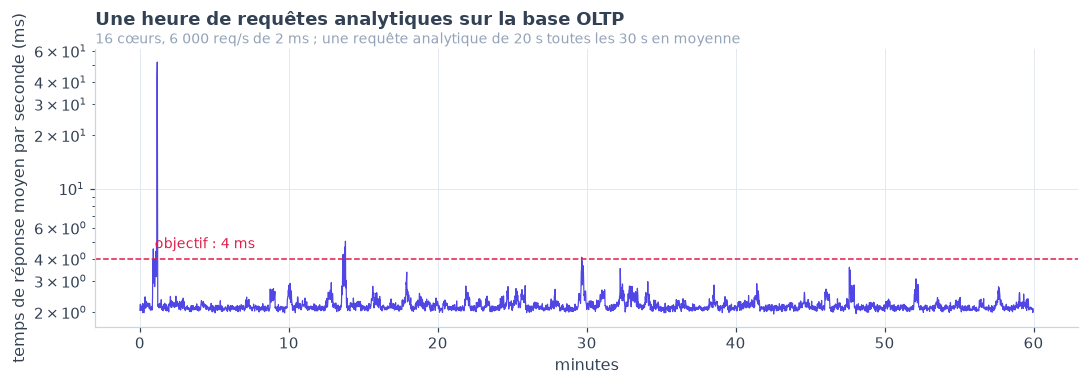

secondes hors objectif : 0.3%


In [4]:
T = 3600.0
olap_t = np.cumsum(rng.exponential(30, 200)); olap_t = olap_t[olap_t < T]
arr = np.cumsum(rng.exponential(1 / lam, int(lam * T * 1.05))); arr = arr[arr < T]
t_all = np.concatenate([arr, olap_t]); s_all = np.concatenate([rng.exponential(1 / mu, arr.size), np.full(olap_t.size, 20.0)])
is_olap = np.concatenate([np.zeros(arr.size, bool), np.ones(olap_t.size, bool)])
o = np.argsort(t_all, kind="stable")
_, end = ar.fifo_servers(t_all[o], s_all[o], c=c)
resp = (end - t_all[o])[~is_olap[o]]
sec = np.floor(t_all[o][~is_olap[o]]).astype(int)
mean_s = pd.Series(resp * 1e3).groupby(sec).mean()
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.semilogy(mean_s.index / 60, mean_s.values, color=INDIGO, lw=0.8)
ax.axhline(4, color=ROSE, ls="--", lw=1); ax.text(1, 4.6, "objectif : 4 ms", color=ROSE, fontsize=9)
ax.set_xlabel("minutes"); ax.set_ylabel("temps de réponse moyen par seconde (ms)")
ax.set_title("Une heure de requêtes analytiques sur la base OLTP")
subtitle(ax, "16 cœurs, 6 000 req/s de 2 ms ; une requête analytique de 20 s toutes les 30 s en moyenne")
plt.tight_layout(); plt.show()
print(f"secondes hors objectif : {(mean_s > 4).mean():.1%}")

La simulation montre des pics isolés, au-delà de 4 ms, chaque fois que quatre requêtes
analytiques se chevauchent ; la part de secondes hors objectif est du même ordre que les
0,5 % calculés (un peu moins ici : un épisode à quatre requêtes doit durer quelques
secondes avant que la file ne déborde, et le hasard d'une seule heure simulée joue).

> **À retenir.** Une base « chargée à 75 % » n'a de marge que pour trois cœurs
> monopolisés sur seize. Le nombre de requêtes analytiques simultanées est aléatoire (loi de Poisson) :
> même une moyenne faible produit régulièrement des chevauchements qui violent l'objectif.

## Exercice 1.3 : instantanés contre flux de modifications

**Énoncé.** Le prix de chaque produit d'un catalogue change en moyenne 3 fois par jour
(processus de Poisson). L'entrepôt est alimenté par un instantané complet chaque nuit à
minuit, chargé en 2 heures.

1. Quelle fraction des prix successifs l'entrepôt voit-il ?
2. Un analyste interroge l'entrepôt à un instant uniforme de la journée. Quel est l'âge
   moyen des données qu'il voit ?
3. À quelle fréquence faudrait-il prendre des instantanés pour voir 90 % des versions ?
   Que penser du résultat ?
4. Quelle est l'alternative, et quel âge moyen obtient-on si chaque modification est
   transmise en 5 secondes ?

**Rappels.** Fraction capturée par un instantané toutes les $T$ :
$f(x) = (1 - e^{-x})/x$ avec $x = \lambda T$ (`ar.snapshot_capture_fraction`) ; l'âge des
données vaut l'attente jusqu'au prochain chargement, plus sa durée (cours 2, section 2 ;
section *Data Warehousing*).

**Solution.**

*1.* $x = 3$ : $f(3) = (1 - e^{-3})/3 \approx 0{,}317$. L'entrepôt ne voit qu'un prix sur
trois.

*2.* Les données disponibles à l'instant $t$ (en heures après minuit) proviennent de
l'instantané de minuit, disponible à 2 h. Entre 2 h et 24 h, l'âge vaut $t$ ; entre 0 h et
2 h, on voit encore l'instantané de la veille, d'âge $t + 24$. Âge moyen :
$\frac{1}{24}\left(\int_0^2 (t + 24)\,dt + \int_2^{24} t\,dt\right) = \frac{50 + 286}{24} = 14$ heures.

*3.* Il faut $f(x) = 0{,}9$, soit $x \approx 0{,}21$ (résolution numérique ci-dessous) :
$T = 0{,}21 / 3$ jour $\approx 1{,}7$ heure. Mais un instantané complet du catalogue prend
2 heures : on ne peut pas en prendre plus souvent qu'on ne sait les charger. Et même à
cette fréquence, 10 % des versions resteraient invisibles. L'instantané est structurellement
inadapté à l'historique.

*4.* La **capture de changements** (CDC) transmet chaque modification : toutes les
versions sont vues, et l'âge moyen tombe à 5 secondes.

**Vérification** : résolution numérique, puis simulation de trajectoires de prix.

f(3) = 0.317 ; x pour 90 % = 0.215 -> T = 1.72 h
simulation : fraction vue = 0.316 ; âge moyen = 13.99 h


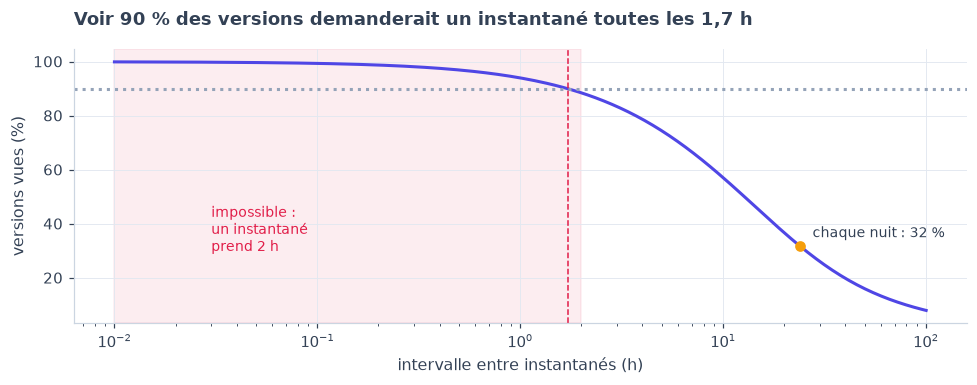

In [5]:
lo, hi = 1e-6, 5.0                                   # bissection : f est décroissante
for _ in range(60):
    mid = (lo + hi) / 2
    lo, hi = (mid, hi) if ar.snapshot_capture_fraction(mid, 1) > 0.9 else (lo, mid)
x90 = (lo + hi) / 2
print(f"f(3) = {ar.snapshot_capture_fraction(3, 1):.3f} ; x pour 90 % = {x90:.3f} -> T = {x90 / 3 * 24:.2f} h")

n_prod, days = 2000, 30
caught = total = 0
for _ in range(n_prod):
    t = np.cumsum(rng.exponential(1 / 3, 200)); t = t[t < days]
    total += t.size
    caught += np.unique(np.floor(t)).size           # une version par jour vue à minuit (la dernière)
tq = rng.uniform(0, 24, 100_000)
age = np.where(tq < 2, tq + 24, tq)
print(f"simulation : fraction vue = {caught / total:.3f} ; âge moyen = {age.mean():.2f} h")

T_h = np.logspace(-2, 2, 200)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.semilogx(T_h, [ar.snapshot_capture_fraction(3 * h / 24, 1) * 100 for h in T_h], color=INDIGO)
ax.axhline(90, color=GRAY, ls=":"); ax.axvline(x90 / 3 * 24, color=ROSE, ls="--", lw=1)
ax.axvspan(1e-2, 2, color=ROSE, alpha=0.08); ax.text(0.03, 30, "impossible :\nun instantané\nprend 2 h", color=ROSE, fontsize=9)
ax.plot(24, ar.snapshot_capture_fraction(3, 1) * 100, "o", color=AMBER); ax.annotate("chaque nuit : 32 %", (24, 31.7), (8, 6), textcoords="offset points", fontsize=9)
ax.set_xlabel("intervalle entre instantanés (h)"); ax.set_ylabel("versions vues (%)")
ax.set_title("Voir 90 % des versions demanderait un instantané toutes les 1,7 h")
plt.tight_layout(); plt.show()

La simulation retrouve la fraction de 32 % et l'âge moyen de 14 heures. La zone rose
rappelle la contrainte physique : un instantané complet ne peut pas être plus fréquent que
son temps de chargement.

> **À retenir.** Un instantané nocturne voit une version sur trois d'un enregistrement qui
> change trois fois par jour, et sert des données de 14 heures d'âge moyen. Seul un flux de
> modifications restitue l'historique et rend les données fraîches.

## Exercice 1.4 : écrire un lac de données sur un object store

**Énoncé.** Une application produit 50 To d'événements par jour, en messages de 2 Ko.
On veut les verser dans un lac sur un object store (tarifs indicatifs : 0,023 $ par Go et
par mois, 0,005 $ pour 1 000 PUT, 0,0004 $ pour 1 000 GET ; latence de premier octet
30 ms, 100 Mo/s par flux).

1. Combien coûtent par mois les **écritures** si chaque message devient un objet ? Et si
   l'on regroupe les messages en fichiers de 128 Mo ?
2. Comparer au coût de stockage d'un mois de données (conservées 30 jours).
3. Un analyste relit une journée entière avec 64 flux parallèles. Combien de temps
   faut-il dans chacun des deux cas ?
4. Quel prix paie-t-on en regroupant ? Comment le limiter ?

**Rappels.** Coût par requête et par Go stocké (`ar.object_store_monthly_cost`) ; temps de
lecture d'un objet $\approx$ latence $+$ taille/débit (`ar.transfer_time`) ; il faut des
objets de plusieurs mégaoctets pour amortir la latence (cours 3, section 4 ; section
*Separation of storage and compute*).

**Solution.**

*1.* Messages individuels : $50 \cdot 10^{12} / 2\,000 = 2{,}5 \cdot 10^{10}$ objets par
jour, soit $7{,}5 \cdot 10^{11}$ par mois, à 0,005 $ les 1 000 : **3,75 millions de
dollars par mois**. En fichiers de 128 Mo : $50 \cdot 10^{12} / 1{,}28 \cdot 10^8
\approx 390\,600$ objets par jour, $1{,}17 \cdot 10^7$ par mois : environ **59 $ par mois**.

*2.* En régime permanent, 30 jours $\times$ 50 To = 1,5 Po stockés, soit
$1{,}5 \cdot 10^6 \times 0{,}023 \approx 34\,500$ $ par mois. Les écritures individuelles
coûteraient cent fois le stockage ; regroupées, une part négligeable.

*3.* Une journée = 50 To. Petits objets : chaque GET coûte $30\text{ ms} + 2\text{ Ko}/(100\text{ Mo/s})
\approx 30{,}02$ ms ; $2{,}5 \cdot 10^{10}$ GET sur 64 flux : $1{,}2 \cdot 10^7$ s, soit
**136 jours**. Gros objets : $30\text{ ms} + 1{,}28$ s par fichier, 390 600 fichiers sur
64 flux : environ $8\,000$ s, soit **2,2 heures** (le débit domine). Les GET coûtent
10 000 $ contre 0,16 $.

*4.* Le regroupement introduit un **délai** : un message attend que son fichier soit
plein (à 50 To/jour, soit 580 Mo/s, un fichier de 128 Mo se remplit en un quart de
seconde si toutes les écritures convergent vers un seul tampon, mais en plusieurs minutes
s'il y a un tampon par partition). On le borne par un délai maximal (fermer le fichier au
bout de N secondes même s'il n'est pas plein) et on sert les données toutes fraîches
depuis un autre système (flux d'événements, cours 2). C'est le compromis fraîcheur contre
efficacité du cours 1.

**Vérification numérique** avec les fonctions du module.

In [6]:
day = 50e12
rows = []
for label, size in [("messages de 2 Ko", 2e3), ("fichiers de 1 Mo", 1e6), ("fichiers de 128 Mo", 128e6)]:
    bill = ar.object_store_monthly_cost(30 * day, size, reads_per_month=0)          # écritures d'un mois
    n_day = day / size
    lat, bw = ar.STORAGE_TIERS["object store"]
    read_h = n_day * ar.transfer_time(size, lat, bw) / 64 / 3600
    rows.append({"découpage": label, "objets par jour": n_day, "PUT ($/mois)": bill["ecritures"],
                 "stockage 30 j ($/mois)": bill["stockage"], "relire une journée, 64 flux (h)": read_h,
                 "GET d'une journée ($)": n_day / 1000 * 0.0004})
pd.DataFrame(rows).set_index("découpage")

,objets par jour,PUT ($/mois),stockage 30 j ($/mois),"relire une journée, 64 flux (h)",GET d'une journée ($)
découpage,,,,,
messages de 2 Ko,2.500e+10,3.750e+06,34500.0,3257.378,10000.000
fichiers de 1 Mo,5.000e+07,7.500e+03,34500.0,8.681,20.000
fichiers de 128 Mo,3.906e+05,5.859e+01,34500.0,2.221,0.156


Les chiffres confirment le calcul : 3,75 M$ contre une soixantaine de dollars pour les
écritures, 136 jours contre deux heures pour relire une journée. Même des fichiers de
1 Mo restent nettement sous-optimaux (la latence pèse encore autant que le transfert).

> **À retenir.** Sur un object store, la taille des objets fixe à la fois la facture et le
> débit : il faut regrouper les petits messages en fichiers de dizaines ou centaines de
> mégaoctets, et accepter (en le bornant) le délai de regroupement.

## Exercice 1.5 : graphe de dérivation, recalculs et effacement

**Énoncé.** Une entreprise décrit ses flux de données ainsi (source -> dérivée) :

- `comptes` -> `cache sessions`, `comptes` -> `index annuaire`, `comptes` -> `lac` ;
- `commandes` -> `lac`, `lac` -> `entrepôt`, `entrepôt` -> `ventes par région` (agrégat
  sans identifiant personnel), `entrepôt` -> `features`, `features` -> `modèle churn`,
  `modèle churn` -> `scores clients` ;
- `catalogue` -> `index produits`.

1. Quels jeux recalculer, et dans quel ordre, quand `commandes` change ?
2. Une équipe propose d'ajouter l'arc `scores clients` -> `comptes` (écrire le score
   dans la fiche client). Pourquoi est-ce dangereux pour la notion de système de
   référence ? Que dit le graphe ?
3. Un client demande l'effacement de ses données. Lister les jeux à purger, sachant que
   seuls `comptes` et `commandes` contiennent des données personnelles à l'origine, et
   que `ventes par région` est un agrégat anonyme.

**Rappels.** Une donnée dérivée se reconstruit depuis sa source ; quand une source change,
ses descendants sont à recalculer dans un ordre topologique (`ar.rebuild_order`) ; un
système de référence détient la version qui fait autorité (cours 2, section 6 ; section
*Systems of Record and Derived Data*) ; l'effacement doit atteindre toutes les dérivées
(cours 5, section 3).

**Solution.**

*1.* Descendants de `commandes` : `lac`, `entrepôt`, puis `ventes par région` et
`features`, puis `modèle churn`, puis `scores clients`. Tout ordre topologique convient,
par exemple celui calculé ci-dessous.

*2.* L'arc crée un **cycle** : `comptes` -> `lac` -> `entrepôt` -> `features` ->
`modèle churn` -> `scores clients` -> `comptes`. Le graphe n'est plus acyclique, il
n'existe plus d'ordre de recalcul, et `comptes` n'est plus une pure source de vérité :
une partie de son contenu devient dérivée de lui-même, à travers un modèle. Une
modification d'un compte relance une boucle de recalculs, et l'on ne sait plus ce qui
fait autorité. Si l'on veut servir le score dans la fiche client, mieux vaut le garder
comme donnée dérivée distincte (une colonne ou une table à part, recalculable, que
l'application joint à la lecture).

*3.* À purger : les deux sources personnelles et tous leurs descendants, **sauf** les
agrégats anonymes : `comptes`, `commandes`, `cache sessions`, `index annuaire`, `lac`,
`entrepôt`, `features`, `modèle churn` (à réentraîner), `scores clients`. `ventes par
région` et `catalogue`, `index produits` ne sont pas concernés (l'agrégat sera recalculé
de toute façon, mais il ne contient pas la personne).

**Vérification (mini-lab)** avec networkx.

1. ordre de recalcul : lac -> entrepôt -> ventes par région -> features -> modèle churn -> scores clients
2. acyclique avant : True ; après : False ; cycle : comptes -> lac -> entrepôt -> features -> modèle churn -> scores clients
3. à purger : ['cache sessions', 'commandes', 'comptes', 'entrepôt', 'features', 'index annuaire', 'lac', 'modèle churn', 'scores clients']


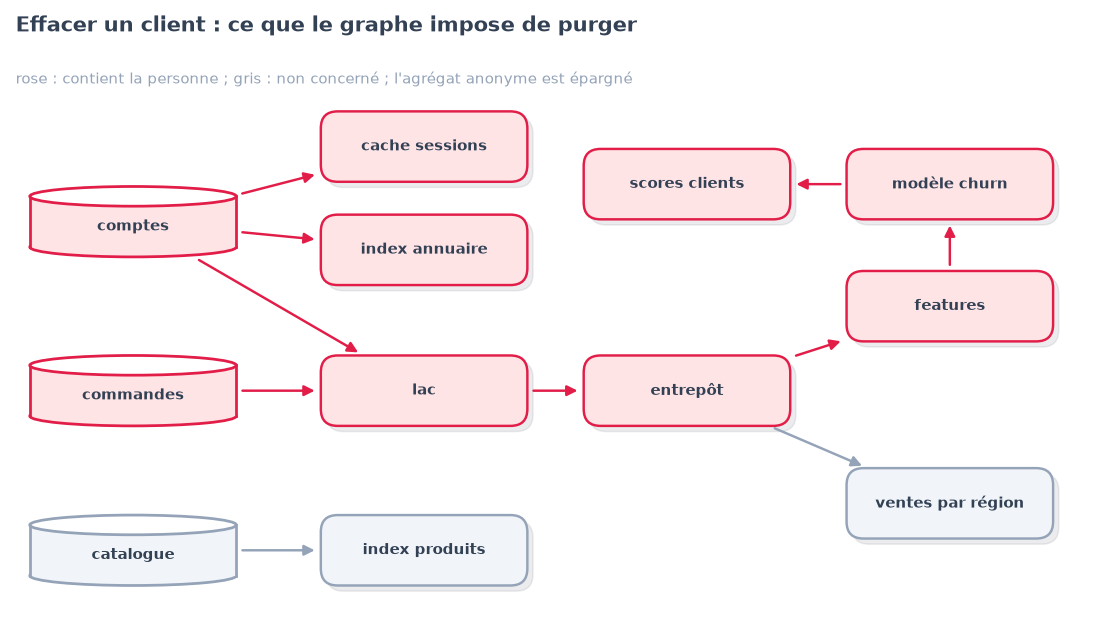

In [7]:
G = nx.DiGraph([("comptes", "cache sessions"), ("comptes", "index annuaire"), ("comptes", "lac"),
                ("commandes", "lac"), ("lac", "entrepôt"), ("entrepôt", "ventes par région"),
                ("entrepôt", "features"), ("features", "modèle churn"), ("modèle churn", "scores clients"),
                ("catalogue", "index produits")])
print("1. ordre de recalcul :", " -> ".join(ar.rebuild_order(G, "commandes")))
G2 = G.copy(); G2.add_edge("scores clients", "comptes")
print("2. acyclique avant :", nx.is_directed_acyclic_graph(G), "; après :", nx.is_directed_acyclic_graph(G2),
      "; cycle :", " -> ".join(u for u, _ in nx.find_cycle(G2, "comptes")))
personal = {"comptes", "commandes"}
anonymous = {"ventes par région"}
to_purge = set(personal)
for s in personal:
    to_purge |= nx.descendants(G, s)
to_purge -= anonymous
print("3. à purger :", sorted(to_purge))

pos = {"comptes": (1.3, 4.2), "commandes": (1.3, 2.4), "catalogue": (1.3, 0.7),
       "cache sessions": (4.4, 5.0), "index annuaire": (4.4, 3.9), "lac": (4.4, 2.4), "index produits": (4.4, 0.7),
       "entrepôt": (7.2, 2.4), "ventes par région": (10.0, 1.2), "features": (10.0, 3.3),
       "modèle churn": (10.0, 4.6), "scores clients": (7.2, 4.6)}
d = Diagram(11.6, 5.5, title="Effacer un client : ce que le graphe impose de purger",
            subtitle="rose : contient la personne ; gris : non concerné ; l'agrégat anonyme est épargné")
for n, (x, y) in pos.items():
    col = ROSE if n in to_purge else GRAY
    d.box(n, x, y, n, color=col, w=2.2, h=0.75, kind="db" if n in personal | {"catalogue"} else "box", fontsize=9.5)
for a, b in G.edges:
    d.arrow(a, b, color=ROSE if b in to_purge else GRAY)
d.show()

> **À retenir.** Un graphe de dérivation explicite répond mécaniquement à trois
> questions : quoi recalculer (les descendants), dans quel ordre (topologique), et quoi
> purger lors d'un effacement. Un cycle signale qu'une source de vérité dépend d'elle-même :
> à éviter.